# Simulazione MC di frange di intensità luminosità - Giornata 2
## Fase Preliminare

Il numero di punti è: 161
I valori di x, y e sigma_y sono tutti finiti: True, True, True
Le incertezze sono tutte positive: True
Le posizioni sono ordinate: True
Intervallo di x: [-5.0, 5.0]
Intervallo di y: [19.834, 420.005]


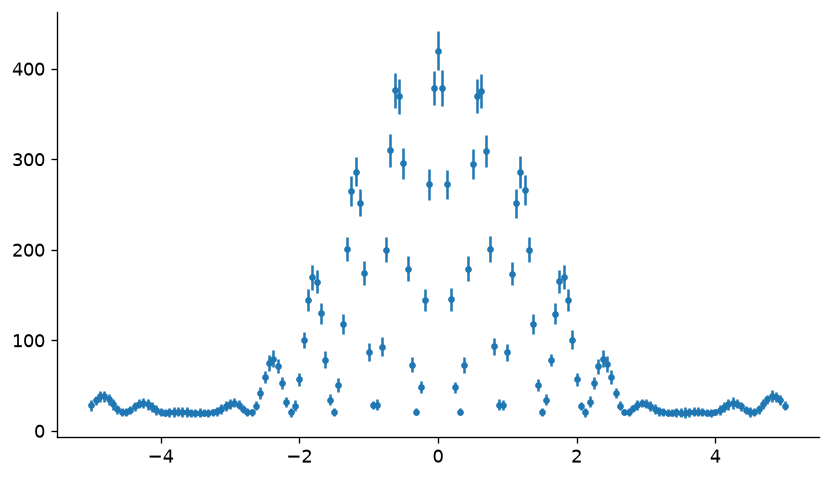

In [88]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
ARANCIONE = "#FFA500"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)

dati = np.genfromtxt(
"dati.csv",
delimiter=",",
names=True
)
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

print(f"Il numero di punti è: {len(x)}")
print(f"I valori di x, y e sigma_y sono tutti finiti: {np.all(np.isfinite(x))}, {np.all(np.isfinite(y))}, {np.all(np.isfinite(sigma_y))}")
print(f"Le incertezze sono tutte positive: {np.all(sigma_y > 0)}")
print(f"Le posizioni sono ordinate: {np.all(np.diff(x) > 0)}")
print(f"Intervallo di x: [{np.min(x)}, {np.max(x)}]")
print(f"Intervallo di y: [{np.min(y)}, {np.max(y)}]")

fig, ax = plt.subplots()
ax.errorbar(x, y, yerr=sigma_y, fmt=".", label="Simulazione dati con errori")
plt.show()

In [89]:
B = np.median(y[np.abs(x) > 2.5])
I0 = np.max(y) - B
alpha = 1
delta = 5

lower = [0.0, 0.0, 0.10, 1.0] # B0 I0 alpha delta
upper = [np.inf, np.inf, 3.0, 12.0]

if(B < lower[0] or B > upper[0]):
    print(f"Il valore di B = {B} è fuori dai limiti [{lower[0]}, {upper[0]}]")
if(I0 < lower[1] or I0 > upper[1]):
    print(f"Il valore di I0 = {I0} è fuori dai limiti [{lower[1]}, {upper[1]}]")    
if(alpha < lower[2] or alpha > upper[2]):
    print(f"Il valore di alpha = {alpha} è fuori dai limiti [{lower[2]}, {upper[2]}]")
if(delta < lower[3] or delta > upper[3]):
    print(f"Il valore di delta = {delta} è fuori dai limiti [{lower[3]}, {upper[3]}]")




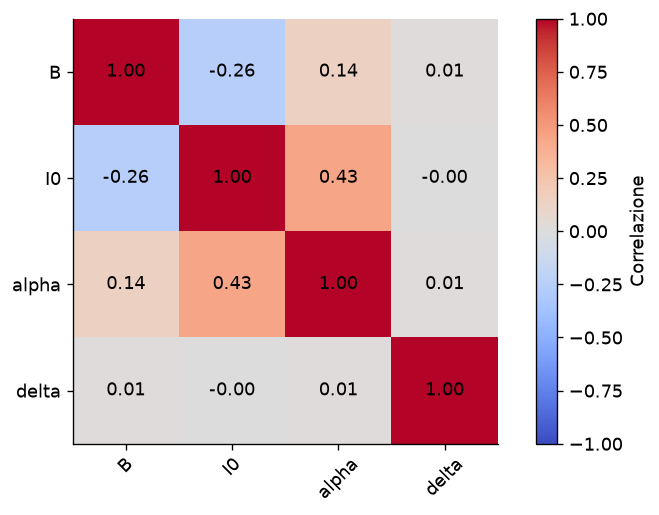

In [90]:
def E(x, alpha):
    return np.sinc(alpha * x / np.pi) ** 2

def C(x, delta):
    return np.cos(delta * x) ** 2

def mu(x, B, I0, alpha, delta):
    mu_values = B + I0 * E(x, alpha) * C(x, delta)

    np.all(np.isfinite(mu_values))  # valori finiti
    np.all(mu_values >= 0)  # valori positivi
    np.allclose(mu_values, mu_values[::-1])  # valori simmetrici

    return mu_values

popt, pcov = curve_fit(mu, x, y, 
                       p0=[B, I0, alpha, delta], 
                       sigma=sigma_y, 
                       absolute_sigma=True, 
                       maxfev=100000, 
                       bounds=(lower, upper))


optimal_B, optimal_I0, optimal_alpha, optimal_delta = popt
optimal_B_err, optimal_I0_err, optimal_alpha_err, optimal_delta_err = np.sqrt(np.diag(pcov))

corr = pcov / np.outer(np.sqrt(np.diag(pcov)), np.sqrt(np.diag(pcov)))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
labels = ["B", "I0", "alpha", "delta"]

plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)

plt.colorbar(label="Correlazione")
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr[i, j]:.2f}",
                 ha="center", va="center")

plt.show()


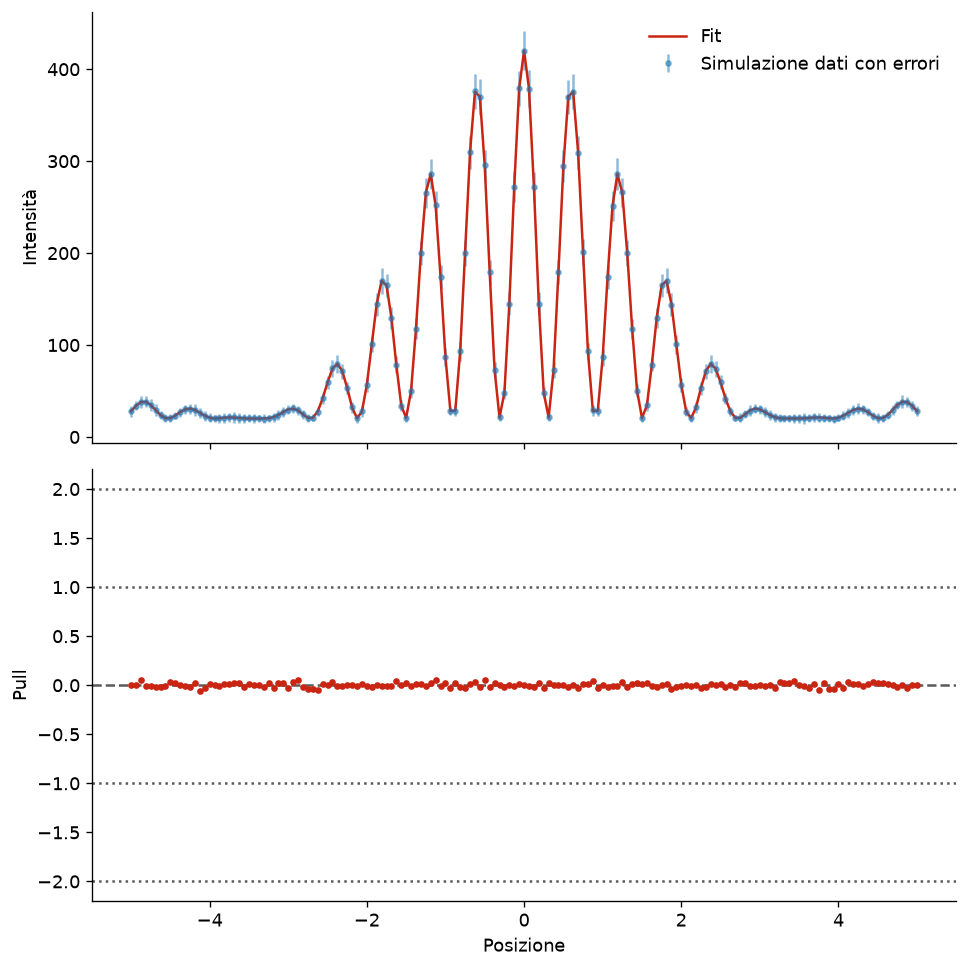

In [91]:
r = y - mu(x, *popt)
pull = r / sigma_y
chi2 = np.sum(pull**2)
dof = len(x) - len(popt)
chi2_red = chi2 / dof
p_value = stats.chi2.sf(chi2, dof)

fig, ax = plt.subplots(2, 1, figsize=(8.2, 8.2), sharex=True)
ax[0].errorbar(x, y, yerr=sigma_y, fmt=".", alpha=0.5, label="Simulazione dati con errori")
ax[0].plot(x, mu(x, *popt), color=ROSSO, label="Fit")
ax[0].set_ylabel("Intensità")
ax[0].legend()
ax[1].errorbar(x, pull, fmt=".", color=ROSSO)
ax[1].axhline(0, color=GRIGIO, linestyle="--")
ax[1].axhline(1, color=GRIGIO, linestyle=":")
ax[1].axhline(-1, color=GRIGIO, linestyle=":")
ax[1].axhline(2, color=GRIGIO, linestyle=":")
ax[1].axhline(-2, color=GRIGIO, linestyle=":")
ax[1].set_xlabel("Posizione")
ax[1].set_ylabel("Pull")
plt.tight_layout()
